## Historical data and GOTTHARD/GMD alignment

Compilation only; no numerical reproduction is claimed. Historical source: `/home/mmanresa/glycine26`, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Cell numbers below are zero-based and include Markdown cells. Run sections in order from a fresh kernel only in the separately approved reproduction stage. Historical inputs are read-only. Review memory before executing: historical loaders materialize full files/runs. Do not run full raw-data processing on login/display nodes.

## Setup

Local pinned helpers replace historical imports and path discovery. No historical config import or source-HDF5 write-back is included. Dependencies: NumPy, SciPy, h5py, Matplotlib and a Jupyter Python kernel. Notebook magic is omitted; plotting calls and source styles are retained. Caches are redirected inside this project.

In [11]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path('/home/mmanresa/FLASH_Gotthard')
if not (PROJECT_ROOT / 'AGENTS.md').is_file():
    raise RuntimeError(f'Project root unavailable: {PROJECT_ROOT}')
sys.dont_write_bytecode = True
os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / '.cache' / 'matplotlib')
os.environ['XDG_CACHE_HOME'] = str(PROJECT_ROOT / '.cache')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from historical import config
from historical import config as path_config
from historical.data_loading import ExperimentData, load_raw_h5, load_data, _align_by_tID
from historical.binning import arb_bool_ar, bin_and_average, bin_and_sum_ratio

print('Historical data:', config.DATA_ROOT)
print('Project:', PROJECT_ROOT)


Historical data: /asap3/flash/gpfs/fl24/2026/data/11022188
Project: /home/mmanresa/FLASH_Gotthard


## Raw and processed structures

Source: `analysis/notebooks/inspect_one_raw_h5_keys.ipynb`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; cells 2–4.

Inspect dataset keys, shapes and dtypes only. Raw spectra are (train, frame, pixel); static products are (section, padded shot, pixel).

Adaptations: Explicit data root; numeric file ordering matches load_raw_h5; extend visitor to known products.

In [12]:
import re
RUN_NO = 58780
FILE_INDEX = 0
raw_dir = config.RAW_H5_DIR
files = sorted(raw_dir.glob(f'*run{RUN_NO}_*.h5'),
               key=lambda p: int(re.search(r'_file(\d+)_', p.name).group(1)))
if not files:
    raise FileNotFoundError(f'No raw H5 files for run {RUN_NO} in {raw_dir}')
H5_PATH = files[FILE_INDEX]
print('Using:', H5_PATH)


Using: /asap3/flash/gpfs/fl24/2026/data/11022188/raw/hdf/online-0/fl2user1/FLASH2_USER1_main_run58780_file1_20260603T100002.1.h5


In [13]:
# Top-level keys only.
with h5py.File(H5_PATH, "r") as f:
    for k in f.keys():
        print(k)


Electron Diagnostic
FL1
FL2
Timing
uncategorised
zraw


In [14]:
# All keys recursively, with shape and dtype for datasets.
def show(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(f"{name}  shape={obj.shape}  dtype={obj.dtype}")
    else:
        print(f"{name}/")

with h5py.File(H5_PATH, "r") as f:
    f.visititems(show)


Electron Diagnostic/
Electron Diagnostic/Undulator setting/
Electron Diagnostic/Undulator setting/SASE02 gap/
Electron Diagnostic/Undulator setting/SASE02 gap/index  shape=(65,)  dtype=uint32
Electron Diagnostic/Undulator setting/SASE02 gap/value  shape=(65,)  dtype=float32
Electron Diagnostic/Undulator setting/SASE02 k value/
Electron Diagnostic/Undulator setting/SASE02 k value/index  shape=(65,)  dtype=uint32
Electron Diagnostic/Undulator setting/SASE02 k value/value  shape=(65,)  dtype=float32
Electron Diagnostic/Undulator setting/SASE03 k value/
Electron Diagnostic/Undulator setting/SASE03 k value/index  shape=(65,)  dtype=uint32
Electron Diagnostic/Undulator setting/SASE03 k value/value  shape=(65,)  dtype=float32
Electron Diagnostic/Undulator setting/SASE04 k value/
Electron Diagnostic/Undulator setting/SASE04 k value/index  shape=(65,)  dtype=uint32
Electron Diagnostic/Undulator setting/SASE04 k value/value  shape=(65,)  dtype=float32
Electron Diagnostic/Undulator setting/SASE05

In [15]:
COMBINED_H5 = config.COMBINED_DIR / 'interferometry_scan_from-15000_to15000_speed100.h5'
STATIC_PRODUCTS = [config.XAS_STATIC_DIR / name for name in (
    'run58780_static_xas.h5', 'run58793_static_xas.h5',
    'run58794_static_xas.h5', 'reference_frame.h5')]
for product in [COMBINED_H5, *STATIC_PRODUCTS]:
    print('\nPRODUCT:', product)
    with h5py.File(product, 'r') as f:
        f.visititems(show)
        for key in ('run_no', 'signal_bunch_range', 'gmd_signal_bunch_range',
                    'gmd_bunch_start', 'vls_bunch_roll', 'vls_crop_roi', 'raw_dir'):
            print(key, f.attrs.get(key, '<not recorded>'))
        for key in ('ml/vls_bunch_index', 'ml/gmd_bunch_index', 'ml/train_id'):
            if key in f:
                print(key, f[key][0, :35])



PRODUCT: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/interferometry_scan_from-15000_to15000_speed100.h5
between_tdc_files  shape=(81772,)  dtype=bool
gmd  shape=(81772, 110)  dtype=float32
hor_pos  shape=(81772,)  dtype=float32
local_DAQ_running  shape=(81772,)  dtype=bool
mpe  shape=(81772,)  dtype=float32
tID  shape=(81772,)  dtype=float64
ver_pos  shape=(81772,)  dtype=float32
vls  shape=(81772, 110, 1280)  dtype=float32
z  shape=(81772, 110)  dtype=float32
z_std  shape=(81772, 110)  dtype=float32
run_no <not recorded>
signal_bunch_range <not recorded>
gmd_signal_bunch_range <not recorded>
gmd_bunch_start <not recorded>
vls_bunch_roll <not recorded>
vls_crop_roi <not recorded>
raw_dir <not recorded>

PRODUCT: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58780_static_xas.h5
gmd  shape=(33, 44400)  dtype=float64
gmd_tunnel  shape=(33, 44400)  dtype=float64
ml/
ml/feature_names  shape=(26,)  dtype=object
ml/feature_roles  shape=(26,)  dtype=object

## Train matching and detector metadata

Source: `analysis/scripts/data_loading.py`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; _align_by_tID, load_raw_h5.

VLS train IDs are the config-2 master. Matching train IDs does not establish pulse/frame correspondence.

Adaptations: Expose existing matcher with small metadata reads and checks of its sorted-ID assumption.

In [16]:
VLS_BASE = '/FL2/Support Infrastructure/Gotthard/images'
GMD_BASE = '/FL2/Photon Diagnostic/GMD/Pulse resolved energy/energy hall'
with h5py.File(H5_PATH, 'r') as f:
    master_tID = f[VLS_BASE + '/index'][:]
    gmd_idx = f[GMD_BASE + '/index'][:]
    print('VLS:', f[VLS_BASE + '/value'].shape, f[VLS_BASE + '/value'].dtype)
    print('GMD:', f[GMD_BASE + '/value'].shape, f[GMD_BASE + '/value'].dtype)
    print('GMD attributes:', dict(f[GMD_BASE + '/value'].attrs))
    for label, ids in [('VLS', master_tID), ('GMD', gmd_idx)]:
        print(label, 'duplicate IDs:', len(ids) - len(np.unique(ids)))
        if np.any(np.diff(ids.astype(np.int64)) < 0):
            raise ValueError(f'{label} IDs are unsorted: searchsorted assumption fails')
    matched, src_pos = _align_by_tID(gmd_idx, master_tID)
    print('Matched trains:', int(matched.sum()), '/', len(master_tID))
    print('Matched IDs:', master_tID[matched][:5], gmd_idx[src_pos][:5])
    for name in ('delay', 'exposure', 'frames', 'period'):
        key = f'/FL2/Support Infrastructure/Gotthard/{name}/value'
        if key in f:
            print(key, f[key].shape, dict(f[key].attrs), f[key][:5])


VLS: (4330, 110, 1280) uint16
GMD: (4513, 8, 30) float32
GMD attributes: {'DAQ name': 'FLASH.FEL/XGM.INTENSITY/FL2.HALL', 'DOOCS name': 'INTENSITY.TD, INTENSITY_AUX.TD, X.TD, Y.TD, INTENSITY.SIGMA.TD, X.SIGMA.TD, Y.SIGMA.TD, TSS', 'columns': 'INTENSITY.TD:0, INTENSITY_AUX.TD:1, X.TD:2, Y.TD:3, INTENSITY.SIGMA.TD:4, X.SIGMA.TD:5, Y.SIGMA.TD:6, TSS:7', 'description': 'Intensity per pulse (all pulses), Intensity per pulse (aux, all pulses), Position horizontal (all pulses), Position vertical (all pulses), Sigma of Intensity per pulse (all pulses), Sigma of horizontal position (all pulses), Sigma of vertical position (all pulses), Combined warning and error flags', 'dim': '0, 1, 2, 3, 4, 5, 6, 7', 'units': 'au, au, mm, mm, au, mm, mm, none'}
VLS duplicate IDs: 0
GMD duplicate IDs: 0
Matched trains: 4330 / 4330
Matched IDs: [2657120149 2657120150 2657120151 2657120152 2657120153] [2657120149 2657120150 2657120151 2657120152 2657120153]
/FL2/Support Infrastructure/Gotthard/delay/value (62,) 

## Raw loading and individual frames

Source: `analysis/notebooks/inspect_raw_vls.ipynb`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; cells 3, 5, 8, 9.

Run 58780: 110 frames, pixel ROI [450,650), signal frames [10,40), roll 0. No background subtraction here; raw loader leaves delay z as NaN.

Adaptations: Use existing MAX_FILES preview option with 1 instead of None. Keep train_idx=4000 and fail if unavailable. Correct misleading source comment; omit invalid data.keys() and old same-index GMD correlation.

In [17]:
# Raw-only simplified workflow for single-energy inspection.
CONFIG = 2
RUN_NO = 58780

RAW_DIR = Path(path_config.RAW_H5_DIR)
TRAIN_LENGTH = 110
N_VLS_PIXELS = 1280
MAX_FILES = 1

# Same settings as xas_static configs/scripts.
CROP_ROI = (450, 650)
SIGNAL_BUNCH_RANGE = (10, 40)
BG_BUNCH_RANGE = (50, 100)
VLS_BUNCH_ROLL = 0

print(f'raw dir           : {RAW_DIR}')
print(f'run               : {RUN_NO}')
print(f'train length      : {TRAIN_LENGTH}')
print(f'max files         : {MAX_FILES}')
print(f'crop roi          : {CROP_ROI}')
print(f'signal bunch range: {SIGNAL_BUNCH_RANGE}')
print(f'bg bunch range    : {BG_BUNCH_RANGE}')
print(f'vls bunch roll    : {VLS_BUNCH_ROLL}')

raw dir           : /asap3/flash/gpfs/fl24/2026/data/11022188/raw/hdf/online-0/fl2user1
run               : 58780
train length      : 110
max files         : 1
crop roi          : (450, 650)
signal bunch range: (10, 40)
bg bunch range    : (50, 100)
vls bunch roll    : 0


In [18]:
data = load_raw_h5(
    run_no=RUN_NO,
    config=CONFIG,
    raw_dir=RAW_DIR,
    train_length=TRAIN_LENGTH,
    n_vls_pixels=N_VLS_PIXELS,
    max_files=MAX_FILES,
)

if not isinstance(data, ExperimentData):
    raise TypeError('Expected ExperimentData from data_loading.load_raw_h5.')

# Raw quicklook: crop, optional bunch roll, then keep signal frames. No background subtraction.
data_xas = (
    data
    .crop_vls(*CROP_ROI)
    .roll_vls_bunches(VLS_BUNCH_ROLL)
    .trim_bunches(*SIGNAL_BUNCH_RANGE)
)

print('source mode: raw')
print(f'config         : {data.config}')
print(f'n_trains       : {data.n_trains}')
print(f'n_bunches raw  : {data.n_bunches}')
print(f'raw vls shape  : {data.vls.shape if data.vls is not None else None}')
print(f'xas vls shape  : {data_xas.vls.shape if data_xas.vls is not None else None}')
print(f'xas pixels     : {int(data_xas.vls_pixels[0])} .. {int(data_xas.vls_pixels[-1])}')
print(f'signal bunches : {SIGNAL_BUNCH_RANGE} -> {data_xas.n_bunches} bunches kept')

Loading 1 raw H5 file(s) for run 58780 (config 2).
  reading FLASH2_USER1_main_run58780_file1_20260603T100002.1.h5
Loaded 4330 trains x 110 bunches.
source mode: raw
config         : 2
n_trains       : 4330
n_bunches raw  : 110
raw vls shape  : (4330, 110, 1280)
xas vls shape  : (4330, 30, 200)
xas pixels     : 450 .. 649
signal bunches : (10, 40) -> 30 bunches kept


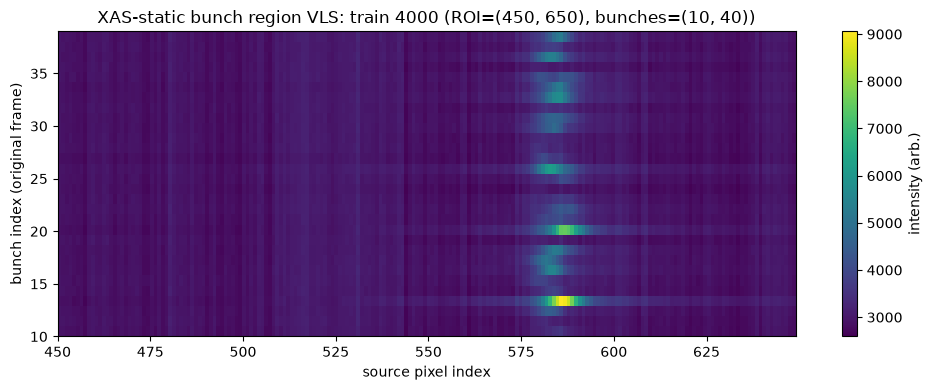

In [19]:
if data_xas.vls is None:
    raise RuntimeError('No VLS in this dataset. Use CONFIG=2.')

train_idx = 4000
if not 0 <= train_idx < data_xas.n_trains:
    raise IndexError("Historical train_idx=4000 unavailable in selected input")
vls_train = data_xas.vls[train_idx]  # (signal_bunches, n_pixels)

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(
    vls_train,
    aspect='auto',
    origin='lower',
    cmap='viridis',
    extent=[data_xas.vls_pixels[0], data_xas.vls_pixels[-1], SIGNAL_BUNCH_RANGE[0], SIGNAL_BUNCH_RANGE[1] - 1],
)
fig.colorbar(im, ax=ax, label='intensity (arb.)')
ax.set_title(
    f'XAS-static bunch region VLS: train {train_idx} '
    f'(ROI={CROP_ROI}, bunches={SIGNAL_BUNCH_RANGE})'
 )
ax.set_xlabel('source pixel index')
ax.set_ylabel('bunch index (original frame)')
fig.tight_layout()
plt.show()

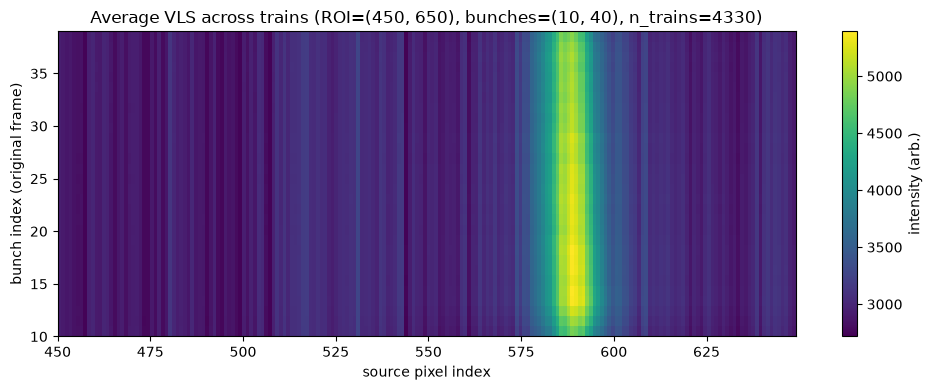

avg-over-trains shape: (30, 200)


In [20]:
if data_xas.vls is None:
    raise RuntimeError('No VLS in this dataset. Use CONFIG=2.')

# Average over trains first -> (signal_bunches, n_pixels).
vls_avg_over_trains = np.nanmean(data_xas.vls, axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(
    vls_avg_over_trains,
    aspect='auto',
    origin='lower',
    cmap='viridis',
    extent=[data_xas.vls_pixels[0], data_xas.vls_pixels[-1], SIGNAL_BUNCH_RANGE[0], SIGNAL_BUNCH_RANGE[1] - 1],
)
fig.colorbar(im, ax=ax, label='intensity (arb.)')
ax.set_title(
    f'Average VLS across trains '
    f'(ROI={CROP_ROI}, bunches={SIGNAL_BUNCH_RANGE}, n_trains={data_xas.n_trains})'
 )
ax.set_xlabel('source pixel index')
ax.set_ylabel('bunch index (original frame)')
fig.tight_layout()
plt.show()

print(f'avg-over-trains shape: {vls_avg_over_trains.shape}')

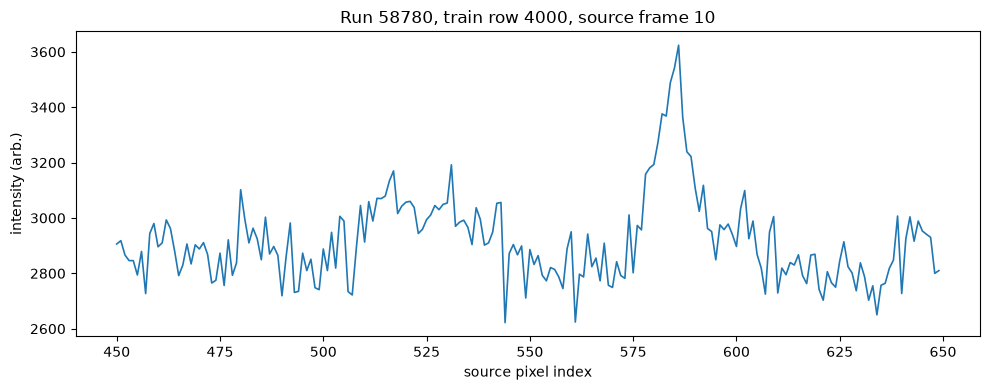

In [21]:
frame_idx = 0  # first selected frame = original frame 10 in this section
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(data_xas.vls_pixels, vls_train[frame_idx], lw=1.2)
ax.set_xlabel('source pixel index')
ax.set_ylabel('intensity (arb.)')
ax.set_title(f'Run {RUN_NO}, train row {train_idx}, source frame {SIGNAL_BUNCH_RANGE[0] + frame_idx}')
fig.tight_layout()
plt.show()


## Explicit frame/pulse windows

Source: `analysis/scripts/compute_static_xas.py`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; compute_static_xas; configs/xas_static/{no_sample_03June,5mmol_gly_03June_night}.py.

58780/58794: VLS [10,40) → GMD [0,30), roll 0. Run 58793 has older product provenance: do not assign it a mapping silently. reference_frame.h5 records runs 58870/58871 with VLS [2,102) → GMD [0,100), roll 0. Comparisons 58815/58816 instead roll −2 and keep [0,101). Roll wraps raw frames 0–1 into the tail; retain the historical windows. These conventions have not independently validated physical timing.

Adaptations: Inspect the existing separate selection/flatten operations on raw arrays without shutter or background processing; data.gmd is already train-matched channel 0.

In [22]:
if RUN_NO != 58780:
    raise ValueError('Select the documented run-specific mapping before changing RUN_NO')
GMD_BUNCH_START = 0
sig_b0, sig_b1 = SIGNAL_BUNCH_RANGE
gmd_b0 = int(GMD_BUNCH_START)
gmd_b1 = gmd_b0 + (sig_b1 - sig_b0)
A_block = data_xas.vls  # raw cropped spectra, no section-background subtraction
G_block = data.gmd[:, gmd_b0:gmd_b1]
if A_block.shape[:2] != G_block.shape:
    raise ValueError('Selected detector/GMD shot axes disagree')
A_flat = A_block.reshape(-1, A_block.shape[-1])
G_flat = G_block.reshape(-1)
train_id_flat = np.repeat(data.tID.astype(np.int64), sig_b1 - sig_b0)
vls_bunch_flat = np.tile(np.arange(sig_b0, sig_b1), data.n_trains)
gmd_bunch_flat = np.tile(np.arange(gmd_b0, gmd_b1), data.n_trains)
print('A, G:', A_block.shape, G_block.shape)
print('First frame/pulse pairs:', list(zip(vls_bunch_flat[:30], gmd_bunch_flat[:30])))
print('Finite selected GMD:', int(np.isfinite(G_flat).sum()))
print('Finite GMD under older identical-index selection:',
      int(np.isfinite(data.gmd[:, sig_b0:sig_b1]).sum()))


A, G: (4330, 30, 200) (4330, 30)
First frame/pulse pairs: [(np.int64(10), np.int64(0)), (np.int64(11), np.int64(1)), (np.int64(12), np.int64(2)), (np.int64(13), np.int64(3)), (np.int64(14), np.int64(4)), (np.int64(15), np.int64(5)), (np.int64(16), np.int64(6)), (np.int64(17), np.int64(7)), (np.int64(18), np.int64(8)), (np.int64(19), np.int64(9)), (np.int64(20), np.int64(10)), (np.int64(21), np.int64(11)), (np.int64(22), np.int64(12)), (np.int64(23), np.int64(13)), (np.int64(24), np.int64(14)), (np.int64(25), np.int64(15)), (np.int64(26), np.int64(16)), (np.int64(27), np.int64(17)), (np.int64(28), np.int64(18)), (np.int64(29), np.int64(19)), (np.int64(30), np.int64(20)), (np.int64(31), np.int64(21)), (np.int64(32), np.int64(22)), (np.int64(33), np.int64(23)), (np.int64(34), np.int64(24)), (np.int64(35), np.int64(25)), (np.int64(36), np.int64(26)), (np.int64(37), np.int64(27)), (np.int64(38), np.int64(28)), (np.int64(39), np.int64(29))]
Finite selected GMD: 129900
Finite GMD under older 

## Basic selection API

Source: `analysis/scripts/experiment_data.py`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; filter_trains, filter_shots, valid_shots, n_valid_shots.

Demonstrate original bad-train filtering and NaN-GMD masking with no intensity cut. Raw mode has all-False between_tdc_files; identity rows below retain their original order.

Adaptations: Separate inspection container binds the explicitly paired GMD window; no upstream array mutation.

In [23]:
from dataclasses import replace
paired = replace(data_xas, gmd=G_block)
selected = paired.filter_trains(paired.between_tdc_files.astype(int), lo=0, hi=0)
selected = selected.filter_shots(selected.gmd, lo=-np.inf, hi=np.inf)
print('Selected trains:', selected.n_trains, 'valid shots:', selected.n_valid_shots)
print('Mask:', selected.valid_shots.shape)
if selected.n_trains != paired.n_trains:
    raise ValueError('Raw-mode identity display expects no dropped trains')
print('First retained identities:', np.column_stack(
    (train_id_flat, vls_bunch_flat, gmd_bunch_flat))[selected.valid_shots.ravel()][:5])


Selected trains: 4330 valid shots: 129900
Mask: (4330, 30)
First retained identities: [[2657120149         10          0]
 [2657120149         11          1]
 [2657120149         12          2]
 [2657120149         13          3]
 [2657120149         14          4]]


## Combined versus raw loading

Source: `write_h5.py`, main @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`; main, DataChunkConfig2, _advance_to; data_loading.py::load_data; delay_compare_runs.ipynb cell 3.

The writer aligns raw streams and SDU logs by train ID, stores native within-train positions, and does not establish a universal pulse offset. Config-2 writer defaults: train_length=110, data_bunches=101. main load_data removes bad trains and trims/downsamples, but does not restore local_DAQ_running. Do not import the writer: it needs legacy decoders and writes outputs.

Adaptations: Read existing combined product only; trim=2/downsample=100 follow delay_compare_runs. No roll, background, delay conversion or DAQ correction is applied in this inspection section.

In [24]:
del data, data_xas, paired, selected, A_block, G_block, A_flat, G_flat, vls_train
combined = load_data(str(COMBINED_H5), config=2,
                     trim_start=2, trim_end=2, downsample_N=100)
for name in ('tID', 'gmd', 'mpe', 'z', 'between_tdc_files', 'vls'):
    value = getattr(combined, name)
    print(name, value.shape, value.dtype)
with h5py.File(COMBINED_H5, 'r') as f:
    if 'local_DAQ_running' in f:
        print('local_DAQ_running:', f['local_DAQ_running'].shape, f['local_DAQ_running'][:10])
print('Combined preview only; no delay analysis.')


tID (818,) float64
gmd (818, 110) float32
mpe (818,) float32
z (818, 110) float32
between_tdc_files (818,) bool
vls (818, 110, 1280) float32
local_DAQ_running: (81772,) [ True  True  True  True  True  True  True  True  True  True]
Combined preview only; no delay analysis.


## Interactive raw-frame / native-pulse diagnostic (independent section)

Run **this section alone**, starting at its parameter cell; the earlier historical workflows are unchanged.
It samples raw HDF5 selectively and produces two figures. All windows are **half-open original frame indices**.
Offset convention: **raw GOTTHARD frame = native GMD pulse index + offset**. No rolling, wrapped pairs,
GMD division or processed-file writes are used. Train-ID matching is a separate operation.

Source: project-developed `validation/pulse_alignment_20261020/diagnose.py::{read_run, dark_image,
residual, paired, corr, sweep}` and `REPORT.md`, 2026-10-20. This is the tested investigation diagnostic,
**not a historical processing method**. Train matching reuses `historical.data_loading._align_by_tID`
from historical `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`.
Adaptations: configurable dimensions/windows/channels; stream ROI sums instead of retaining images;
keep the tested per-file position standardization and common-train subtraction; two compact figures.

The editable values below are an **explicit run-58815 example**, not defaults for new acquisitions.
For a new run, check the ROI, schema/channel meanings, dark applicability, and all windows.
The pedestal window used for the diagnostic is deliberately separate from the background being tested.
A mean-light threshold is descriptive: frame-dependent pedestals can mimic illumination. Correlation
supports a candidate correspondence, but does not establish absolute timing or authorize a processing change.


In [25]:
# EDIT HERE: all numerical settings for the independent diagnostic.
import os
import sys
from pathlib import Path
PROJECT_ROOT = Path('/home/mmanresa/FLASH_Gotthard').resolve()
sys.dont_write_bytecode = True
os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / '.cache/matplotlib')
os.environ['XDG_CACHE_HOME'] = str(PROJECT_ROOT / '.cache')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import h5py
import numpy as np
import matplotlib.pyplot as plt
from historical.data_loading import _align_by_tID

ALIGN_RUN = 58794
ALIGN_RAW_DIR = Path('/asap3/flash/gpfs/fl24/2026/data/11022188/raw/hdf/online-0/fl2user1')
ALIGN_MAX_FILES = 5                    # evenly spaced files, then evenly spaced rows per file
ALIGN_TRAINS_PER_FILE = 64
ALIGN_READ_BLOCK = 16                 # maximum detector trains per HDF5 read
ALIGN_PIXEL_ROI = (450, 650)
ALIGN_GMD_CHANNEL = 0                 # historical hall pulse energy; verify for a new schema
ALIGN_VALIDITY_CHANNEL = 7            # historical TSS: finite nonzero warns; None disables
ALIGN_VALIDITY_VALUE = 0
ALIGN_REJECT_MISSING_FLAGS = False   # tested method: padded NaNs are not finite warning flags
ALIGN_OFFSETS = np.arange(-5, 16)      # raw frame = native GMD index + offset
ALIGN_SIGNAL_WINDOW = (2, 103)        # proposed original-frame signal window
ALIGN_BACKGROUND_WINDOW = (103, 110)  # historical later background, intentionally tested for light
ALIGN_PEDESTAL_WINDOW = (103, 110)     # independent diagnostic baseline; NOT a production change
ALIGN_DARK_FILE = ALIGN_RAW_DIR / 'FLASH2_USER1_main_run58814_file1_20260605T232039.1.h5'
# Set ALIGN_DARK_FILE = None if no applicable measured dark is available; this is reported.
ALIGN_DARK_TRAINS = 128
ALIGN_HISTORICAL_OFFSETS = {58794: 10, 58815: 2, 58816: 2, 58870: 2, 58871: 2}
ALIGN_REFERENCE_OFFSET = ALIGN_HISTORICAL_OFFSETS.get(ALIGN_RUN)  # optional comparison only
ALIGN_MEAN_SEM_THRESHOLD = 5.0         # descriptive, not an automatic selection
ALIGN_MEAN_PEAK_FRACTION = 0.01
ALIGN_MIN_PAIRS = 10
ALIGN_SCATTER_GRIDSIZE = 40
ALIGN_VLS_KEY = '/FL2/Support Infrastructure/Gotthard/images'
ALIGN_GMD_KEY = '/FL2/Photon Diagnostic/GMD/Pulse resolved energy/energy hall'
print('Run:', ALIGN_RUN, '| raw directory:', ALIGN_RAW_DIR.resolve())
print('ROI:', ALIGN_PIXEL_ROI, '| proposed signal/background:', ALIGN_SIGNAL_WINDOW, ALIGN_BACKGROUND_WINDOW)
print('Diagnostic pedestal:', ALIGN_PEDESTAL_WINDOW, '| measured dark:', ALIGN_DARK_FILE)
print('GMD/validity channels:', ALIGN_GMD_CHANNEL, ALIGN_VALIDITY_CHANNEL, '| offsets:', ALIGN_OFFSETS)


Run: 58794 | raw directory: /asap3/flash/gpfs/fl24/2026/data/11022188/raw/hdf/online-0/fl2user1
ROI: (450, 650) | proposed signal/background: (2, 103) (103, 110)
Diagnostic pedestal: (103, 110) | measured dark: /asap3/flash/gpfs/fl24/2026/data/11022188/raw/hdf/online-0/fl2user1/FLASH2_USER1_main_run58814_file1_20260605T232039.1.h5
GMD/validity channels: 0 7 | offsets: [-5 -4 -3 -2 -1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]


### Bounded loading and explicit indices

Arrays retained: `align_raw_sum[train, original_frame]`, `align_gmd[train, native_pulse]`,
`align_train_ids`, `align_source_rows`, `align_file_group`, and `align_files`.
Only the requested ROI is read, in small train blocks. Shapes must agree across sampled files;
unexpected schemas, duplicate/unsorted IDs and invalid windows fail explicitly. No padding is invented.
Dark-frame ROI means are subtracted first, then a **per-train** diagnostic pedestal.
This differs from the global background in historical `vls_compare_runs`; existing analysis is untouched.


In [26]:
import re

def align_checked_ids(dataset):
    values = np.asarray(dataset[:]).reshape(-1)
    if len(np.unique(values)) != len(values) or np.any(np.diff(values.astype(np.int64)) < 0):
        raise ValueError('Unsorted or duplicate train IDs: ' + dataset.name)
    return values

def align_window(window, size, name):
    lo, hi = window
    if not (isinstance(lo, (int, np.integer)) and isinstance(hi, (int, np.integer)) and 0 <= lo < hi <= size):
        raise ValueError(f'{name} must be a nonempty half-open range within [0,{size}): {window}')
    return slice(lo, hi)

# Small repeated operation: stream integrated ROI values, retaining original frame ordering.
def align_read_roi(dataset, rows):
    blocks = []
    for start in range(0, len(rows), ALIGN_READ_BLOCK):
        block = dataset[rows[start:start + ALIGN_READ_BLOCK], :,
                        ALIGN_PIXEL_ROI[0]:ALIGN_PIXEL_ROI[1]]
        blocks.append(block.sum(axis=2, dtype=np.float64))
    return np.concatenate(blocks)



In [27]:
if min(ALIGN_MAX_FILES, ALIGN_TRAINS_PER_FILE, ALIGN_READ_BLOCK, ALIGN_DARK_TRAINS) < 1:
    raise ValueError('Sampling limits must be positive')
align_all_files = sorted(ALIGN_RAW_DIR.glob(f'*run{ALIGN_RUN}_file*.h5'),
                         key=lambda p: int(re.search(r'_file(\d+)_', p.name).group(1)))
if not align_all_files:
    raise FileNotFoundError(f'No raw files for run {ALIGN_RUN} in {ALIGN_RAW_DIR}')
align_file_numbers = np.unique(np.linspace(0, len(align_all_files)-1,
                              min(ALIGN_MAX_FILES, len(align_all_files)), dtype=int))
align_files = [align_all_files[i] for i in align_file_numbers]
align_parts, align_gmd_parts, align_flag_parts = [], [], []
align_ids_parts, align_row_parts, align_group_parts, align_file_info = [], [], [], []
align_unmatched = 0
for group, path in enumerate(align_files):
    with h5py.File(path, 'r') as handle:
        detector = handle[ALIGN_VLS_KEY + '/value']
        monitor = handle[ALIGN_GMD_KEY + '/value']
        master = align_checked_ids(handle[ALIGN_VLS_KEY + '/index'])
        gmd_ids = align_checked_ids(handle[ALIGN_GMD_KEY + '/index'])
        if detector.ndim != 3 or monitor.ndim != 3:
            raise ValueError('Expected detector (train,frame,pixel), GMD (train,channel,pulse)')
        if detector.shape[0] != len(master) or monitor.shape[0] != len(gmd_ids):
            raise ValueError('Dataset/index lengths differ')
        align_window(ALIGN_PIXEL_ROI, detector.shape[2], 'Pixel ROI')
        if not 0 <= ALIGN_GMD_CHANNEL < monitor.shape[1]:
            raise ValueError('GMD channel outside actual channel axis')
        if ALIGN_VALIDITY_CHANNEL is not None and not 0 <= ALIGN_VALIDITY_CHANNEL < monitor.shape[1]:
            raise ValueError('Validity channel outside actual channel axis')
        shape = (detector.shape[1], detector.shape[2], monitor.shape[2])
        if group and shape != align_shape:
            raise ValueError('Acquisition dimensions changed: inspect file groups separately')
        align_shape = shape
        rows = np.unique(np.linspace(0, len(master)-1, min(ALIGN_TRAINS_PER_FILE, len(master)), dtype=int))
        matched, positions = _align_by_tID(gmd_ids, master[rows])
        align_unmatched += int((~matched).sum())
        rows = rows[matched]
        if not len(rows):
            raise ValueError(f'No sampled train matches in {path}')
        align_parts.append(align_read_roi(detector, rows))
        align_gmd_parts.append(monitor[positions, ALIGN_GMD_CHANNEL, :].astype(float))
        flags = (monitor[positions, ALIGN_VALIDITY_CHANNEL, :].astype(float)
                 if ALIGN_VALIDITY_CHANNEL is not None else np.zeros((len(rows), monitor.shape[2])))
        align_flag_parts.append(flags)
        align_ids_parts.append(master[rows]); align_row_parts.append(rows)
        align_group_parts.append(np.full(len(rows), group))
        align_file_info.append({'path': str(path.resolve()), 'detector_shape': detector.shape,
                                'gmd_shape': monitor.shape, 'matched_trains': len(rows)})
        print(path.name, '| shapes:', detector.shape, monitor.shape, '| matched:', len(rows))


FLASH2_USER1_main_run58794_file1_20260603T233702.1.h5 | shapes: (419, 110, 1280) (431, 8, 30) | matched: 64
FLASH2_USER1_main_run58794_file33_20260604T000027.1.h5 | shapes: (419, 110, 1280) (445, 8, 30) | matched: 64
FLASH2_USER1_main_run58794_file65_20260604T002422.1.h5 | shapes: (452, 110, 1280) (452, 8, 30) | matched: 64
FLASH2_USER1_main_run58794_file97_20260604T004850.1.h5 | shapes: (461, 110, 1280) (461, 8, 30) | matched: 64
FLASH2_USER1_main_run58794_file129_20260604T011525.1.h5 | shapes: (125, 110, 1280) (137, 8, 30) | matched: 64


In [28]:
align_raw_sum = np.concatenate(align_parts)
align_gmd = np.concatenate(align_gmd_parts)
align_flags = np.concatenate(align_flag_parts)
align_train_ids = np.concatenate(align_ids_parts)
align_source_rows = np.concatenate(align_row_parts)
align_file_group = np.concatenate(align_group_parts)
if len(np.unique(align_train_ids)) != len(align_train_ids):
    raise ValueError('Duplicate sampled train IDs across files')
align_frame_indices = np.arange(align_shape[0])
align_pulse_indices = np.arange(align_shape[2])
align_warning = np.isfinite(align_flags) & (align_flags != ALIGN_VALIDITY_VALUE)
align_missing_flags = ~np.isfinite(align_flags)
align_invalid = ~np.isfinite(align_gmd) | align_warning
if ALIGN_REJECT_MISSING_FLAGS:
    align_invalid |= align_missing_flags
# When validity filtering is disabled, only nonfinite GMD energies are rejected.
if ALIGN_VALIDITY_CHANNEL is None:
    align_invalid = ~np.isfinite(align_gmd)
align_gmd[align_invalid] = np.nan
align_signal_slice = align_window(ALIGN_SIGNAL_WINDOW, align_shape[0], 'Signal window')
align_background_slice = align_window(ALIGN_BACKGROUND_WINDOW, align_shape[0], 'Background window')
align_pedestal_slice = align_window(ALIGN_PEDESTAL_WINDOW, align_shape[0], 'Diagnostic pedestal window')
align_dark_sum = np.zeros(align_shape[0])
if ALIGN_DARK_FILE is not None:
    with h5py.File(ALIGN_DARK_FILE, 'r') as handle:
        dark = handle[ALIGN_VLS_KEY + '/value']
        if dark.ndim != 3 or dark.shape[1:] != align_shape[:2]:
            raise ValueError('Dark acquisition dimensions differ from signal')
        dark_rows = np.unique(np.linspace(0, dark.shape[0]-1, min(ALIGN_DARK_TRAINS, dark.shape[0]), dtype=int))
        align_dark_sum = align_read_roi(dark, dark_rows).mean(axis=0)
align_dark_corrected = align_raw_sum - align_dark_sum[None, :]
align_pedestal = align_dark_corrected[:, align_pedestal_slice].mean(axis=1, keepdims=True)
align_signal = align_dark_corrected - align_pedestal
print('Retained intensity arrays:', align_signal.shape, align_gmd.shape,
      '| unmatched trains:', align_unmatched, '| invalid GMD entries:', int(align_invalid.sum()))


Retained intensity arrays: (320, 110) (320, 30) | unmatched trains: 0 | invalid GMD entries: 6


### Position-controlled offset sweep

Use the **same native pulse indices for every candidate**, excluding unavailable source frames rather
than wrapping. Each sampled file is standardized separately at each pulse position; each train's mean
standardized component is then removed and positions recentered. These numerical operations are copied
from the investigation. GOTTHARD and GMD are standardized separately, never divided by one another.
Even/odd rows are independent populations of trains (not a guarantee of temporal independence).
Weak or inconsistent subset peaks must remain inconclusive. The sweep's common pulse population can
exclude train edges; the illumination figure still shows **every original frame**.


In [29]:
def align_corr(a,b):
    ok=np.isfinite(a)&np.isfinite(b)
    if ok.sum()<ALIGN_MIN_PAIRS:return float('nan'),int(ok.sum())
    x,y=a[ok],b[ok]
    if np.std(x)==0 or np.std(y)==0:return float('nan'),int(ok.sum())
    return float(np.corrcoef(x,y)[0,1]),int(ok.sum())
def align_residual(a,group,remove_train):
    z=np.full(a.shape,np.nan)
    # Remove per-file pulse-position means/variance so scan drift is not the offset evidence.
    for k in np.unique(group):
        rows=group==k
        x=a[rows].copy()
        mu=np.nanmean(x,axis=0);sd=np.nanstd(x,axis=0)
        sd=np.where(sd>0,sd,np.nan)
        x=(x-mu)/sd
        if remove_train:
            x=x-np.nanmean(x,axis=1,keepdims=True)
            x=x-np.nanmean(x,axis=0,keepdims=True)
        z[rows]=x
    return z
def align_paired(s,g,groups,offset,pulses,remove_train):
    x=s[:,pulses+offset];y=g[:,pulses]
    return align_residual(x,groups,remove_train),align_residual(y,groups,remove_train)


In [30]:
align_offsets = np.asarray(ALIGN_OFFSETS)
if (align_offsets.ndim != 1 or not len(align_offsets) or
        not np.issubdtype(align_offsets.dtype, np.integer) or len(np.unique(align_offsets)) != len(align_offsets)):
    raise ValueError('Offsets must be a nonempty array of unique integers')
align_core_pulses = np.arange(max(0, -int(align_offsets.min())),
                             min(align_gmd.shape[1], align_signal.shape[1]-int(align_offsets.max())))
if len(align_core_pulses) < 2:
    raise ValueError('Too few common pulse positions; narrow the candidate offset range')
align_subsets = {'all': np.ones(len(align_train_ids), dtype=bool),
                 'even trains': np.arange(len(align_train_ids)) % 2 == 0,
                 'odd trains': np.arange(len(align_train_ids)) % 2 == 1}
align_scores, align_pair_counts = {}, {}
for label, rows in align_subsets.items():
    scores, counts = [], []
    for offset in align_offsets:
        x, y = align_paired(align_signal[rows], align_gmd[rows], align_file_group[rows],
                      int(offset), align_core_pulses, True)
        score, count = align_corr(x, y)
        scores.append(score); counts.append(count)
    align_scores[label] = np.asarray(scores)
    align_pair_counts[label] = np.asarray(counts)
if not np.isfinite(align_scores['all']).any():
    raise ValueError('No finite residual correlation; inspect signal, validity and sample size')
align_best_index = int(np.nanargmax(align_scores['all']))
align_best_offset = int(align_offsets[align_best_index])  # diagnostic candidate, NOT accepted processing setting
align_x, align_y = align_paired(align_signal, align_gmd, align_file_group,
                         align_best_offset, align_core_pulses, True)
align_mean = np.nanmean(align_signal, axis=0)
align_sem = np.nanstd(align_signal, axis=0) / np.sqrt(np.isfinite(align_signal).sum(axis=0))
align_mean_gmd = np.nanmean(align_gmd, axis=0)
align_light_threshold = np.maximum(ALIGN_MEAN_SEM_THRESHOLD * align_sem,
                                  ALIGN_MEAN_PEAK_FRACTION * max(float(align_mean.max()), 0))
align_apparent_light = align_mean > align_light_threshold
align_background_indices = align_frame_indices[align_background_slice]
align_overlap = align_background_indices[align_apparent_light[align_background_slice]]
align_geometric_overlap = np.intersect1d(align_frame_indices[align_signal_slice], align_background_indices)


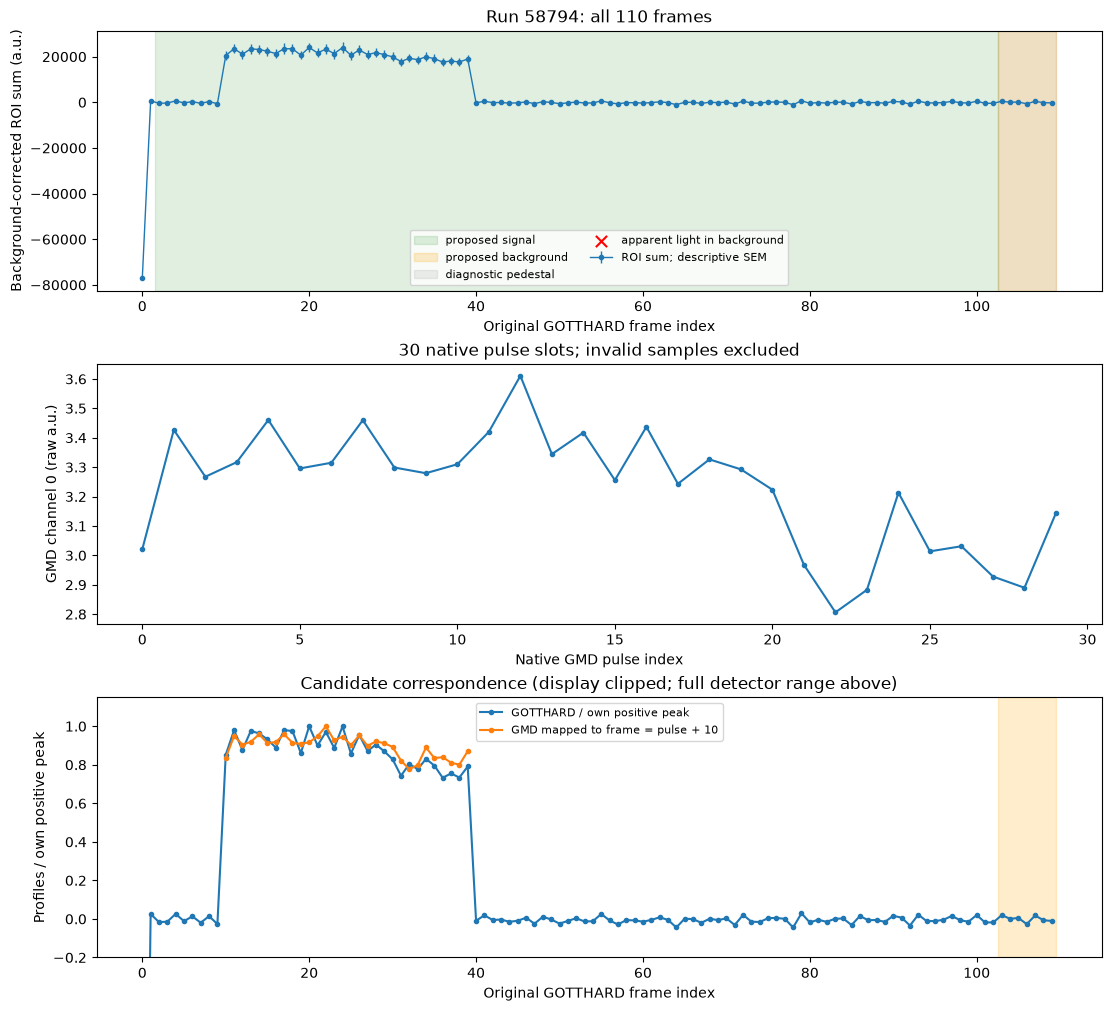

In [31]:
# Figure 1: original acquisition coordinates; proposed windows never trim the arrays.
align_fig1, align_axes1 = plt.subplots(3, 1, figsize=(11, 10), constrained_layout=True)
ax = align_axes1[0]
ax.errorbar(align_frame_indices, align_mean, yerr=align_sem, fmt='.-', lw=1, label='ROI sum; descriptive SEM')
ax.axvspan(ALIGN_SIGNAL_WINDOW[0]-.5, ALIGN_SIGNAL_WINDOW[1]-.5, alpha=.12, color='green', label='proposed signal')
ax.axvspan(ALIGN_BACKGROUND_WINDOW[0]-.5, ALIGN_BACKGROUND_WINDOW[1]-.5, alpha=.2, color='orange', label='proposed background')
ax.axvspan(ALIGN_PEDESTAL_WINDOW[0]-.5, ALIGN_PEDESTAL_WINDOW[1]-.5, alpha=.13, color='gray', label='diagnostic pedestal')
ax.scatter(align_overlap, align_mean[align_overlap], color='red', marker='x', s=65, label='apparent light in background')
ax.set(xlabel='Original GOTTHARD frame index', ylabel='Background-corrected ROI sum (a.u.)', title=f'Run {ALIGN_RUN}: all {len(align_frame_indices)} frames')
ax.legend(fontsize=8, ncol=2)
ax = align_axes1[1]
ax.plot(align_pulse_indices, align_mean_gmd, '.-')
ax.set(xlabel='Native GMD pulse index', ylabel=f'GMD channel {ALIGN_GMD_CHANNEL} (raw a.u.)', title=f'{len(align_pulse_indices)} native pulse slots; invalid samples excluded')
ax = align_axes1[2]
# Peak scaling is for display only, not the offset calculation.
ax.plot(align_frame_indices, align_mean / max(float(align_mean.max()), np.finfo(float).tiny), '.-', label='GOTTHARD / own positive peak')
for offset in sorted({align_best_offset} | ({int(ALIGN_REFERENCE_OFFSET)} if ALIGN_REFERENCE_OFFSET is not None else set())):
    frames = align_pulse_indices + offset
    available = (frames >= 0) & (frames < len(align_frame_indices))
    ax.plot(frames[available], align_mean_gmd[available] / max(float(np.nanmax(align_mean_gmd)), np.finfo(float).tiny),
            '.-', label=f'GMD mapped to frame = pulse + {offset}')
ax.axvspan(ALIGN_BACKGROUND_WINDOW[0]-.5, ALIGN_BACKGROUND_WINDOW[1]-.5, color='orange', alpha=.2)
ax.scatter(align_overlap, align_mean[align_overlap] / max(float(align_mean.max()), np.finfo(float).tiny), color='red', marker='x', s=65)
ax.set(xlabel='Original GOTTHARD frame index', ylabel='Profiles / own positive peak', ylim=(-.2, 1.15),
       title='Candidate correspondence (display clipped; full detector range above)')
ax.legend(fontsize=8)
plt.show()


In [38]:
# --- Diagnose available energies in the loaded alignment sample ---
matched = np.isfinite(align_train_energy_eV)

print(f'Matched trains: {matched.sum():,}/{len(matched):,}')
print(f'Unmatched trains: {(~matched).sum():,}')

if matched.any():
    energies, counts = np.unique(np.round(align_train_energy_eV[matched], 3), return_counts=True)
    print('\nAvailable photon energies:')
    for e, n in zip(energies, counts):
        print(f'  {e:8.3f} eV : {n:5d} trains')

print('\nLoaded train-ID range:', np.min(align_train_ids), 'to', np.max(align_train_ids))
print('Processed train IDs mapped:', len(train_to_energy))

Matched trains: 211/320
Unmatched trains: 109

Available photon energies:
   270.000 eV :    64 trains
   273.500 eV :    64 trains
   277.500 eV :    30 trains
   281.000 eV :    53 trains

Loaded train-ID range: 2657610293 to 2657669336
Processed train IDs mapped: 38808


Matched 211 of 320 sampled trains to photon-energy sections
Available approximate photon-energy settings (eV, sampled trains):
[(270.0, 64), (273.5, 64), (277.5, 30), (281.0, 53)]


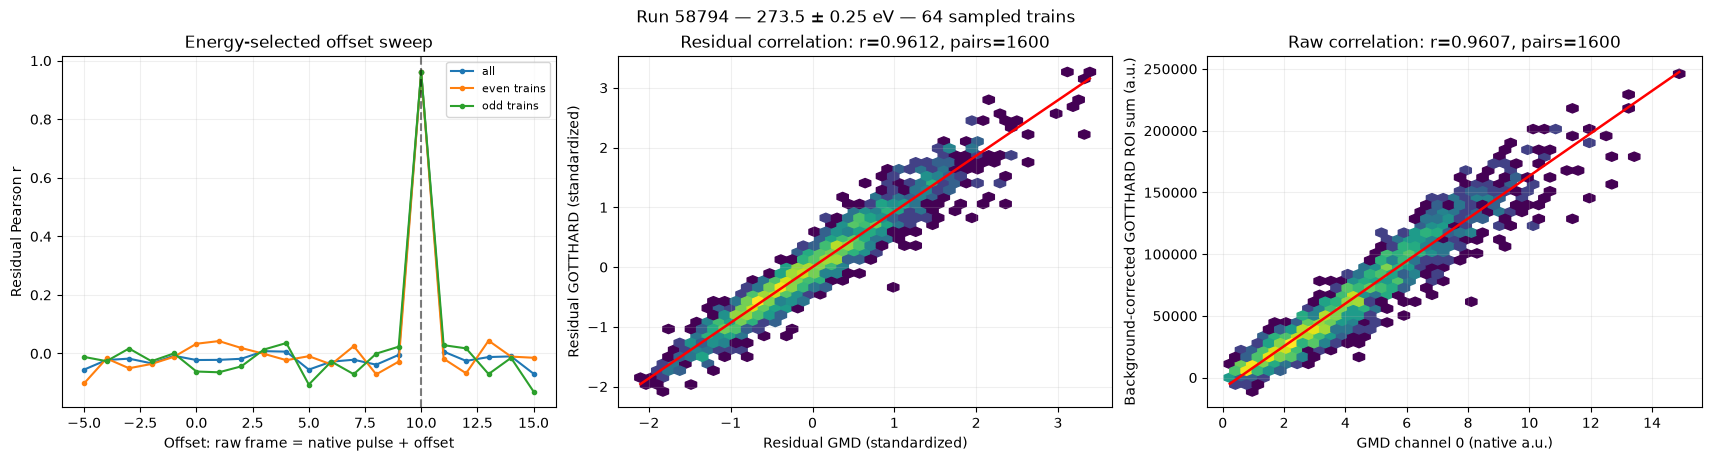

Selected trains: 64 / 320
Best selected-energy offset: +10
Original all-energy best offset: +10


In [37]:
# --- Optional: GOTTHARD/GMD alignment correlations at a selected photon energy ---
ALIGN_CORR_ENERGY_EV = 273.5     # e.g. 275.0; None = all energies
ALIGN_CORR_ENERGY_TOL = 0.25   # eV, selection around recorded photon-energy setpoint

# --- Associate sampled train IDs with the processed scan-section energies ---
# Uses metadata from the existing processed HDF5; does not reload GOTTHARD spectra.

from pathlib import Path

ALIGN_SECTION_H5 = Path(
    '/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5'
)

train_to_energy = {}

with h5py.File(ALIGN_SECTION_H5, 'r') as f:
    section_energies = np.asarray(f['nominal_energies'][:], dtype=float)
    section_counts = np.asarray(f['n_shots'][:], dtype=int)
    train_dataset = f['ml/train_id']

    if train_dataset.ndim != 2 or train_dataset.shape[0] != len(section_energies):
        raise ValueError('Unexpected processed train-ID array shape')

    for sec, (e, n) in enumerate(zip(section_energies, section_counts)):
        if not np.isfinite(e) or n == 0:
            continue
        if n < 0 or n > train_dataset.shape[1]:
            raise ValueError(f'Invalid shot count in section {sec}')

        train_ids = np.unique(train_dataset[sec, :n])
        train_ids = train_ids[train_ids > 0]

        for tid in train_ids:
            tid = int(tid)
            if tid in train_to_energy and not np.isclose(train_to_energy[tid], e, atol=0.002, rtol=0):
                raise ValueError(f'Train {tid} has conflicting section energies')
            train_to_energy[tid] = float(e)

align_train_energy_eV = np.array(
    [train_to_energy.get(int(tid), np.nan) for tid in np.asarray(align_train_ids).ravel()],
    dtype=float
)

if align_train_energy_eV.size != align_signal.shape[0]:
    raise ValueError('Train-energy array does not match sampled GOTTHARD train axis')

print(f'Matched {np.isfinite(align_train_energy_eV).sum():,} of '
      f'{len(align_train_energy_eV):,} sampled trains to photon-energy sections')

finite_energy = np.isfinite(align_train_energy_eV)
if not finite_energy.any():
    raise ValueError('No usable train-energy metadata was recovered')

rounded_energy = np.round(align_train_energy_eV[finite_energy] * 2) / 2
energies, counts = np.unique(rounded_energy, return_counts=True)
print('Available approximate photon-energy settings (eV, sampled trains):')
print(list(zip(energies.tolist(), counts.tolist())))

if ALIGN_CORR_ENERGY_EV is None:
    selected = finite_energy
    selection_label = 'All recorded energies'
else:
    selected = finite_energy & (np.abs(align_train_energy_eV - ALIGN_CORR_ENERGY_EV) <= ALIGN_CORR_ENERGY_TOL)
    selection_label = f'{ALIGN_CORR_ENERGY_EV:g} ± {ALIGN_CORR_ENERGY_TOL:g} eV'

if selected.sum() < 3:
    raise ValueError(f'{selection_label}: only {selected.sum()} matching trains')

s = align_signal[selected]
g = align_gmd[selected]
groups = align_file_group[selected]

# Recalculate the offset sweep for the selected train population.
subsets = {
    'all': np.ones(len(s), dtype=bool),
    'even trains': np.arange(len(s)) % 2 == 0,
    'odd trains': np.arange(len(s)) % 2 == 1,
}
scores_by_group = {}

for label, rows in subsets.items():
    scores = []
    for offset in align_offsets:
        sx, gy = align_paired(s[rows], g[rows], groups[rows],
                              int(offset), align_core_pulses, True)
        r, _ = align_corr(sx, gy)
        scores.append(r)
    scores_by_group[label] = np.asarray(scores)

if not np.isfinite(scores_by_group['all']).any():
    raise ValueError('No valid energy-selected residual correlations')

best_index = int(np.nanargmax(scores_by_group['all']))
best_offset = int(align_offsets[best_index])

# Residual pairs at the selected offset.
res_vls, res_gmd = align_paired(s, g, groups, best_offset, align_core_pulses, True)

# Raw pairs at the same selected offset.
raw_vls = s[:, align_core_pulses + best_offset].ravel()
raw_gmd = g[:, align_core_pulses].ravel()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)

# Left: offset sweep.
for label, scores in scores_by_group.items():
    axes[0].plot(align_offsets, scores, '.-', label=label)
axes[0].axvline(best_offset, color='black', ls='--', alpha=0.5)
axes[0].set(xlabel='Offset: raw frame = native pulse + offset',
            ylabel='Residual Pearson r', title='Energy-selected offset sweep')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

# Centre and right: correlations, using the same selected population.
for ax, x, y, title, xlabel, ylabel in (
    (axes[1], res_gmd.ravel(), res_vls.ravel(), 'Residual correlation',
     'Residual GMD (standardized)', 'Residual GOTTHARD (standardized)'),
    (axes[2], raw_gmd, raw_vls, 'Raw correlation',
     f'GMD channel {ALIGN_GMD_CHANNEL} (native a.u.)',
     'Background-corrected GOTTHARD ROI sum (a.u.)'),
):
    valid = np.isfinite(x) & np.isfinite(y)
    r, n = align_corr(x, y)

    if n >= ALIGN_MIN_PAIRS and np.isfinite(r):
        ax.hexbin(x[valid], y[valid], gridsize=ALIGN_SCATTER_GRIDSIZE,
                  mincnt=1, bins='log', cmap='viridis')
        slope, intercept = np.polyfit(x[valid], y[valid], 1)
        xx = np.linspace(x[valid].min(), x[valid].max(), 200)
        ax.plot(xx, slope*xx + intercept, color='red', lw=1.8)
        ax.set_title(f'{title}: r={r:.4f}, pairs={n}')
    else:
        ax.set_title(f'{title}: insufficient valid pairs ({n})')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)

fig.suptitle(f'Run {ALIGN_RUN} — {selection_label} — {selected.sum()} sampled trains')
plt.show()

print(f'Selected trains: {selected.sum()} / {len(align_train_ids)}')
print(f'Best selected-energy offset: {best_offset:+d}')
print(f'Original all-energy best offset: {align_best_offset:+d}')

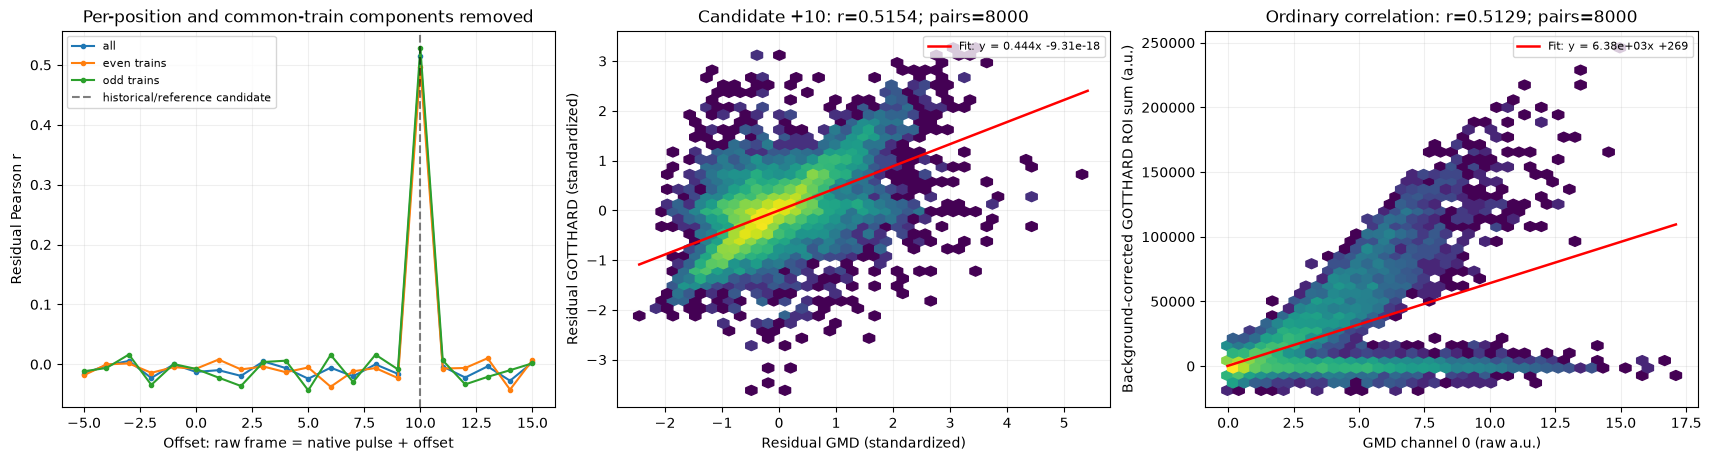

[Residual Fit - Centre Plot] : y = 0.44366x -9.3095e-18 | r = 0.5154 | pairs = 8000
[Raw Data Fit - Right Plot]  : y = 6383.6x +269.08 | r = 0.5129 | pairs = 8000


In [32]:
# Figure 2: retain all sweep scores and residual arrays for interactive inspection.
align_fig2, align_axes2 = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)

# -------------------------------------------------------------------------
# Left Plot: Correlation Scores vs. Offset
# -------------------------------------------------------------------------
ax = align_axes2[0]
for label, scores in align_scores.items():
    ax.plot(align_offsets, scores, '.-', label=label)
if ALIGN_REFERENCE_OFFSET is not None:
    ax.axvline(ALIGN_REFERENCE_OFFSET, color='black', ls='--', alpha=.5, label='historical/reference candidate')
ax.set(xlabel='Offset: raw frame = native pulse + offset', ylabel='Residual Pearson r', title='Per-position and common-train components removed')
ax.legend(fontsize=8); ax.grid(alpha=.2)

# -------------------------------------------------------------------------
# Centre Plot: Residual Correlation (Standardized)
# -------------------------------------------------------------------------
#Removed for each train the average value of the train to correct for train variations
#Removed for each bunch position the average value across trains to correct for bunch position 

ax = align_axes2[1]
align_scatter_valid = np.isfinite(align_x) & np.isfinite(align_y)
align_res_x = align_y[align_scatter_valid]  # Residual GMD
align_res_y = align_x[align_scatter_valid]  # Residual GOTTHARD

ax.hexbin(align_res_x, align_res_y, gridsize=ALIGN_SCATTER_GRIDSIZE, mincnt=1, bins='log', cmap='viridis')

# Linear least-squares fit for Residuals
if len(align_res_x) >= ALIGN_MIN_PAIRS:
    res_fit_slope, res_fit_intercept = np.polyfit(align_res_x, align_res_y, 1)
    res_fit_x_plot = np.linspace(align_res_x.min(), align_res_x.max(), 200)
    ax.plot(res_fit_x_plot, res_fit_slope * res_fit_x_plot + res_fit_intercept,
            color='red', lw=1.8, label=f'Fit: y = {res_fit_slope:.3g}x {res_fit_intercept:+.3g}')
    ax.legend(fontsize=8)

ax.set(xlabel='Residual GMD (standardized)', ylabel='Residual GOTTHARD (standardized)',
       title=f'Candidate {align_best_offset:+d}: r={align_scores["all"][align_best_index]:.4f}; pairs={align_pair_counts["all"][align_best_index]}')
ax.set_axisbelow(True); ax.grid(alpha=.2)

# -------------------------------------------------------------------------
# Right Plot: Raw Correlation (Before Standardization)
# -------------------------------------------------------------------------
align_raw_vls = align_signal[:, align_core_pulses + align_best_offset].ravel()
align_raw_gmd = align_gmd[:, align_core_pulses].ravel()
align_raw_valid = np.isfinite(align_raw_vls) & np.isfinite(align_raw_gmd)
align_raw_r, align_raw_n = align_corr(align_raw_vls, align_raw_gmd)

ax = align_axes2[2]
if align_raw_n >= ALIGN_MIN_PAIRS and np.isfinite(align_raw_r):
    x, y = align_raw_gmd[align_raw_valid], align_raw_vls[align_raw_valid]
    ax.hexbin(x, y, gridsize=ALIGN_SCATTER_GRIDSIZE, mincnt=1, bins='log', cmap='viridis')

    # Linear least-squares fit for Raw values
    raw_fit_slope, raw_fit_intercept = np.polyfit(x, y, 1)
    raw_fit_x = np.linspace(x.min(), x.max(), 200)
    ax.plot(raw_fit_x, raw_fit_slope * raw_fit_x + raw_fit_intercept,
            color='red', lw=1.8, label=f'Fit: y = {raw_fit_slope:.3g}x {raw_fit_intercept:+.3g}')
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, 'Insufficient valid pairs', ha='center', va='center', transform=ax.transAxes)

ax.set(xlabel=f'GMD channel {ALIGN_GMD_CHANNEL} (raw a.u.)',
       ylabel='Background-corrected GOTTHARD ROI sum (a.u.)',
       title=f'Ordinary correlation: r={align_raw_r:.4f}; pairs={align_raw_n}')
ax.set_axisbelow(True); ax.grid(alpha=.2)

plt.show()

# -------------------------------------------------------------------------
# Printed Outputs
# -------------------------------------------------------------------------
print(f"[Residual Fit - Centre Plot] : y = {res_fit_slope:.5g}x {res_fit_intercept:+.5g} | r = {align_scores['all'][align_best_index]:.4f} | pairs = {align_pair_counts['all'][align_best_index]}")
print(f"[Raw Data Fit - Right Plot]  : y = {raw_fit_slope:.5g}x {raw_fit_intercept:+.5g} | r = {align_raw_r:.4f} | pairs = {align_raw_n}")

In [ ]:
# Short diagnostic summary; no setting is accepted or written to a processing configuration.
def align_ranges(indices):
    if not len(indices):
        return 'none'
    groups = np.split(indices, np.flatnonzero(np.diff(indices) > 1) + 1)
    return ', '.join(f'[{group[0]},{group[-1]+1})' for group in groups)

print(f'Run {ALIGN_RUN}: {len(align_train_ids)} matched sampled trains; {align_unmatched} unmatched; '
      f'{int(align_invalid.sum())} invalid GMD entries')
print('Native counts: frames =', len(align_frame_indices), '; GMD pulse slots =', len(align_pulse_indices))
print('Proposed signal:', ALIGN_SIGNAL_WINDOW, '| descriptive mean-light ranges:', align_ranges(np.flatnonzero(align_apparent_light)))
print(f'Best TESTED candidate: offset {align_best_offset:+d}, r={align_scores["all"][align_best_index]:.4f}, '
      f'valid pairs={align_pair_counts["all"][align_best_index]}; common native pulse range '
      f'[{align_core_pulses[0]},{align_core_pulses[-1]+1})')
align_subset_best = {}
for label, scores in align_scores.items():
    if np.isfinite(scores).any():
        index = int(np.nanargmax(scores))
        align_subset_best[label] = int(align_offsets[index])
        print(f'  {label}: offset {align_offsets[index]:+d}, r={scores[index]:.4f}, pairs={align_pair_counts[label][index]}')
    else:
        print(f'  {label}: inconclusive (no finite correlation)')
if len(set(align_subset_best.values())) > 1 or len(align_subset_best) != len(align_subsets):
    print('WARNING: independent subsets disagree or are uninformative; do not accept a common offset.')
if align_best_index in (0, len(align_offsets)-1):
    print('WARNING: maximum is at sweep boundary; inspect/widen candidates before interpretation.')
if len(align_geometric_overlap):
    print('WARNING: proposed signal/background windows overlap at raw frames:', align_ranges(align_geometric_overlap))
if len(align_overlap):
    print('WARNING: apparent residual light in proposed background:', align_ranges(align_overlap))
if np.intersect1d(align_background_indices, align_frame_indices[align_pedestal_slice]).size:
    print('CAUTION: background and diagnostic pedestal share frames; a self-subtracted mean cannot exclude light.')
if ALIGN_DARK_FILE is None:
    print('CAUTION: no measured dark applied; frame-dependent pedestal structure may mimic illumination.')
if ALIGN_VALIDITY_CHANNEL is not None and align_missing_flags.any():
    print('CAUTION: missing/padded validity entries:', int(align_missing_flags.sum()),
          '| reject missing flags:', ALIGN_REJECT_MISSING_FLAGS, '; missing is not proof of valid timing.')
print('Thresholds/SEM are descriptive. Low-signal or pedestal features are not proven FEL pulses. '
      'Correlation is supporting evidence, not physical timing proof. No historical processing settings changed.')


Run 58815: 320 matched sampled trains; 0 unmatched; 0 invalid GMD entries
Native counts: frames = 110 ; GMD pulse slots = 101
Proposed signal: (2, 103) | descriptive mean-light ranges: [2,104)
Best TESTED candidate: offset +2, r=0.9429, valid pairs=28800; common native pulse range [5,95)
  all: offset +2, r=0.9429, pairs=28800
  even trains: offset +2, r=0.9471, pairs=14400
  odd trains: offset +2, r=0.9384, pairs=14400
CAUTION: background and diagnostic pedestal share frames; a self-subtracted mean cannot exclude light.
CAUTION: missing/padded validity entries: 32000 | reject missing flags: False ; missing is not proof of valid timing.
Thresholds/SEM are descriptive. Low-signal or pedestal features are not proven FEL pulses. Correlation is supporting evidence, not physical timing proof. No historical processing settings changed.


For historical checks, use run 58794 with signal `[10,40)`, pedestal/background `[50,100)` and
reference +10; runs 58815/58816/58870 support +2. Run 58871 supports +2 only in informative subsets.
The later example deliberately exposes the historical rolled `[100,108)` background as raw `[102,110)`:
raw102 can contain the last FEL pulse. Reconsider a window only after inspecting the relevant acquisition;
this diagnostic does not alter historical processing or certify processed products automatically.
All-frame means and native counts describe acquisition slots, not a guarantee of light in every slot.
See the investigation report for reference-product pairing issues and detailed robustness tests.
Figures remain in memory (`align_fig1`, `align_fig2`); saving is optional and must stay under this project.


## Acquisition decisions and processing configuration (updated-source review)

Run the independent raw diagnostic above first. Its residual offset sweep, ordinary scatter and plots are unchanged.
Bunch count and offset are **separate measurements**: the historical acquisition changed, but neither “40” nor “100”
is a universal count. Slots, apparent light and reliably paired pulses can differ. A mean threshold can flag readout
structure (e.g. raw103), not just FEL light; low-signal subsets can be inconclusive. Inspect the plots before choosing.

Source interfaces: updated `compute_static_xas.py::main/compute_static_xas` and
`compute_xas_aggregates.py::main/compute_xas_aggregates`, commit `f940ee05ddc9fbbd2b0faa95cc25085608792323`.
The latter now independently selects native GMD from `GMD_BUNCH_START`, rather than copying the VLS slice.
This is configured pairing, not an offset estimator. Project helper `review_diagnostics` validates coordinates only.


In [52]:
from historical import review_diagnostics as review
# Explicit choices after inspecting the plots; None means NOT decided. No automatic acceptance.
ACQ_OFFSET_CHOICE = None
ACQ_SIGNAL_RAW_WINDOW = None       # original detector indices, half-open
ACQ_GMD_NATIVE_WINDOW = None       # native pulse indices, half-open; independent of detector indices
ACQ_BACKGROUND_RAW_WINDOW = None   # original detector indices, half-open
ACQ_ROLL_CHOICE = 0                # an equivalent representation may use roll=-offset
ACQ_CHOICES_REVIEWED = False
ACQ_PREVIEW_EXPORT = None          # optional new project-local .npz path for notebook02; no default write

if 'align_signal' not in globals() or 'align_gmd' not in globals():
    raise RuntimeError('Run the independent raw diagnostic above before this acquisition summary')
print('Run:', ALIGN_RUN, '| sampled matched trains:', len(align_train_ids))
print('Detector frames:', align_signal.shape[1], '| native GMD slots:', align_gmd.shape[1])
print('Descriptive mean-light ranges:', align_ranges(np.flatnonzero(align_apparent_light)))
print('Best TESTED offset:', align_best_offset, '| r:', align_scores['all'][align_best_index])
print('Independent subset candidates:', align_subset_best)
print('Use the full profiles and subset scores; a maximum correlation is not timing proof.')
acq_choices = (ACQ_OFFSET_CHOICE, ACQ_SIGNAL_RAW_WINDOW, ACQ_GMD_NATIVE_WINDOW, ACQ_BACKGROUND_RAW_WINDOW)
if not ACQ_CHOICES_REVIEWED or any(value is None for value in acq_choices):
    print('No processing settings emitted: choose offset/native-pulse/raw-frame windows and confirm review explicitly.')
else:
    acq_settings = review.processing_window_settings(
        align_signal.shape[1], align_gmd.shape[1], ACQ_OFFSET_CHOICE,
        ACQ_SIGNAL_RAW_WINDOW, ACQ_GMD_NATIVE_WINDOW, ACQ_BACKGROUND_RAW_WINDOW, ACQ_ROLL_CHOICE)
    acq_frames = np.arange(*ACQ_SIGNAL_RAW_WINDOW)
    acq_pulses = np.arange(*ACQ_GMD_NATIVE_WINDOW)
    acq_valid = np.isfinite(align_signal[:, acq_frames]) & np.isfinite(align_gmd[:, acq_pulses])
    print('Chosen pairs/train:', len(acq_pulses), '| finite integrated-signal/GMD pairs in sample:', int(acq_valid.sum()))
    print('Apparent light in chosen background:', align_ranges(np.intersect1d(
        np.arange(*ACQ_BACKGROUND_RAW_WINDOW), np.flatnonzero(align_apparent_light))))
    if any(value != ACQ_OFFSET_CHOICE for value in align_subset_best.values()):
        print('WARNING: chosen offset differs from a subset candidate; document why before production.')
    print('COPYABLE ACQUISITION FRAGMENT (not a complete scan configuration):')
    print('RUN_NO =', ALIGN_RUN)
    print('CONFIG = 2')
    print('RAW_DIR =', repr(str(ALIGN_RAW_DIR.resolve())))
    print('CROP_ROI =', ALIGN_PIXEL_ROI)
    for acq_key, acq_value in acq_settings.items():
        print(f'{acq_key} = {acq_value!r}')
    print('This fragment changes neither configurations nor HDF5 products. Background still requires physical review.')


Run: 58815 | sampled matched trains: 320
Detector frames: 110 | native GMD slots: 101
Descriptive mean-light ranges: [2,104)
Best TESTED offset: 2 | r: 0.942922527175929
Independent subset candidates: {'all': 2, 'even trains': 2, 'odd trains': 2}
Use the full profiles and subset scores; a maximum correlation is not timing proof.
No processing settings emitted: choose offset/native-pulse/raw-frame windows and confirm review explicitly.


The common acquisition keys are `VLS_BUNCH_ROLL` (default0), `GMD_BUNCH_START` (default0),
`SIGNAL_BUNCH_RANGE`, `BG_BUNCH_RANGE`, `CROP_ROI`, optional `RAW_DIR`, `MAX_FILES`, `TRAIN_LENGTH`.
The snippet sets actual frame count explicitly; the raw loader otherwise defaults to100 for configuration2.
Ranges refer to **post-roll VLS** and **native GMD** separately. `rolled = (raw + roll) % n_frames`;
raw = native GMD + measured offset. Windows crossing the roll boundary are rejected rather than wrapped silently.

The script interfaces are NOT identical:

| Script | Additional scan settings |
|---|---|
| `compute_static_xas.py` | RUN_NO can be an integer or run list. Supports `SECTION_ENERGY_SOURCE='set_wavelength_1'` or explicit `NOMINAL_ENERGIES`; optional rounding. Writes shot-resolved products. |
| `compute_xas_aggregates.py` | RUN_NO is one integer. Requires explicit `NOMINAL_ENERGIES` AND `GMD_EDGES`; does not implement automatic wavelength section energies. Optional `GROUP_BY_ENERGY=True`. Writes aggregate moments. |

Both also accept shutter/transition settings. Their CLI is `script.py CONFIG.py -o OUTPUT.h5`.
This notebook neither imports nor executes them. Complete the scan-specific fields before use, and choose an
explicit output **inside FLASH_Gotthard**, never their historical default directories. `write_h5.py` is the separate
combined-file writer: train matching and array allocation are not pulse-offset estimation or background selection.

Example translation only: raw signal[2,103), GMD[0,101), background[103,110) can be represented by roll0,
signal(2,103),background(103,110),GMD_START0; or roll−2,signal(0,101),background(101,108),GMD_START0.
This keeps101 pulses (indices0–100). Background suitability is not established merely by this translation.


In [53]:
# Optional bounded diagnostic export for notebook02; never overwrites, never writes historical locations.
import json
if ACQ_PREVIEW_EXPORT is not None:
    acq_export_path = Path(ACQ_PREVIEW_EXPORT).expanduser().resolve()
    if PROJECT_ROOT.resolve() not in acq_export_path.parents or acq_export_path.suffix != '.npz':
        raise ValueError('Choose a .npz output strictly inside FLASH_Gotthard (including symlink targets)')
    if acq_export_path.exists():
        raise FileExistsError(f'Preserve existing preview: {acq_export_path}')
    acq_export_path.parent.mkdir(parents=True, exist_ok=True)
    acq_export_metadata = dict(run=int(ALIGN_RUN), roi=list(ALIGN_PIXEL_ROI),
        diagnostic_bg_raw=list(ALIGN_PEDESTAL_WINDOW), dark_file=None if ALIGN_DARK_FILE is None else str(ALIGN_DARK_FILE),
        gmd_channel=int(ALIGN_GMD_CHANNEL), source_files=[str(path.resolve()) for path in align_files],
        description='Bounded diagnostic ROI sums; sampled dark then trainwise pedestal; not production spectra')
    with acq_export_path.open('xb') as acq_export_stream:
        np.savez(acq_export_stream, meta_json=json.dumps(acq_export_metadata), roi_sum=align_signal,
                 source_frame_indices=align_frame_indices, native_gmd_indices=align_pulse_indices,
                 gmd=align_gmd, train_ids=align_train_ids)
    print('New diagnostic preview:', acq_export_path)


## Optional processed-file GMD provenance (bounded, no substitution)

Updated `static_xas_analysis.py::read_hall_gmd_array/read_hall_gmd_slice/load_static_xas_run` prefers mapped GMD.
Here we deliberately read BOTH sources and leave them unchanged. Coverage refers only to sampled recorded rows
`0:n_shots[section]`, never rectangular padding. Stored identity indices describe the configured association,
not independent physical timing proof. A root/mapped discrepancy cannot be repaired by assuming equal shapes.


In [54]:
from historical import review_diagnostics as review
PROVENANCE_FILES = [config.XAS_STATIC_DIR / name for name in ('run58794_static_xas.h5', 'reference_frame.h5')]
PROVENANCE_MAX_SECTIONS = 3
PROVENANCE_SHOTS_PER_SECTION = 100
PROVENANCE_ORIGINAL_FRAME_COUNT = None  # needed to undo a nonzero stored roll; do not infer from flattened shots
PROVENANCE_EXPECTED_OFFSETS = {'run58794_static_xas.h5': 10, 'reference_frame.h5': 2}  # prior raw evidence; edit/remove for new runs

provenance_results = []
for provenance_path in PROVENANCE_FILES:
    provenance = review.gmd_provenance(provenance_path, PROVENANCE_MAX_SECTIONS,
                                     PROVENANCE_SHOTS_PER_SECTION, PROVENANCE_ORIGINAL_FRAME_COUNT)
    provenance_results.append(provenance)
    print(provenance['path'], '| datasets:', provenance['datasets'])
    print('  stored settings:', provenance['attrs'])
    print('  sampled entries/root finite/mapped finite:', provenance['sampled_entries'],
          provenance['root_finite'], provenance['mapped_finite'])
    print('  root == mapped (including NaNs):', provenance['equal_including_nan'],
          '| max difference on finite pairs:', provenance['finite_pair_max_difference'])
    print('  offsets described by STORED identity:', provenance['stored_identity_offsets'])
    provenance_expected = PROVENANCE_EXPECTED_OFFSETS.get(Path(provenance_path).name)
    if provenance_expected is not None:
        print('  prior raw candidate:', provenance_expected, '| identities consistent:',
              provenance['stored_identity_offsets'] == [provenance_expected])
    if provenance['equal_including_nan'] is False:
        print('  WARNING: sources disagree. Existing baseline loader/results remain unchanged; review before quantitative normalization.')
    if provenance['equal_including_nan'] is None:
        print('  Mapped source absent: root association cannot be independently checked from this product.')
    if provenance['identity_cannot_unroll']:
        print('  Original frame count required to interpret nonzero stored roll.')
print('No GMD source was substituted. Agreement of stored indices is not an experimental timing validation.')


/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5 | datasets: {'gmd': [31, 102720], 'ml/gmd_hall_channels': [31, 102720, 8], 'ml/vls_bunch_index': [31, 102720], 'ml/gmd_bunch_index': [31, 102720]}
  stored settings: {'run_no': np.int64(58794), 'gmd_source': 'ml/gmd_hall_channels[..., 0]', 'gmd_bunch_start': np.int64(0), 'gmd_signal_bunch_range': array([ 0, 30]), 'signal_bunch_range': array([10, 40]), 'bg_bunch_range': array([ 50, 100]), 'vls_bunch_roll': np.int64(0)}
  sampled entries/root finite/mapped finite: 300 300 300
  root == mapped (including NaNs): True | max difference on finite pairs: 0.0
  offsets described by STORED identity: [10.0]
  prior raw candidate: 10 | identities consistent: True
/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/reference_frame.h5 | datasets: {'gmd': [41, 72500], 'ml/gmd_hall_channels': [41, 72500, 8], 'ml/vls_bunch_index': [41, 72500], 'ml/gmd_bunch_index': [41, 72500]}
  stored settings: {'run_no':

## Optional section-energy metadata audit

Adapted from updated `xas_static_energy_section_check.ipynb` cells3/6/8/10. Compare stored section energies,
raw section-energy values and wavelength-derived energies. Metadata samples are bounded per section; they cannot
exclude rare within-section setpoint changes. Repeated energies can be split shutter blocks, not missing data.
A missing intended scan step can only be established against an explicitly supplied scan plan. No labels are changed.


Section input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5 | metadata: {'source': 'set_wavelength_1', 'source_unit': 'nm', 'samples_per_section': 8, 'wavelength_feature_present': True}
 section  nominal_eV  section_raw_eV  shots  setpoint_eV  setpoint_step_eV  duplicate_previous_setpoint  setpoint_label_disagree
       0       284.0      284.000010  79200   284.000010               NaN                        False                    False
       1       283.5      283.499982  35160   283.499982         -0.500027                        False                    False
       2       283.0      282.999987  39000   282.999987         -0.499995                        False                    False
       3       282.5      282.500004  35040   282.500004         -0.499984                        False                    False
       4       282.0      282.000010  35790   282.000010         -0.499994                        False                    False

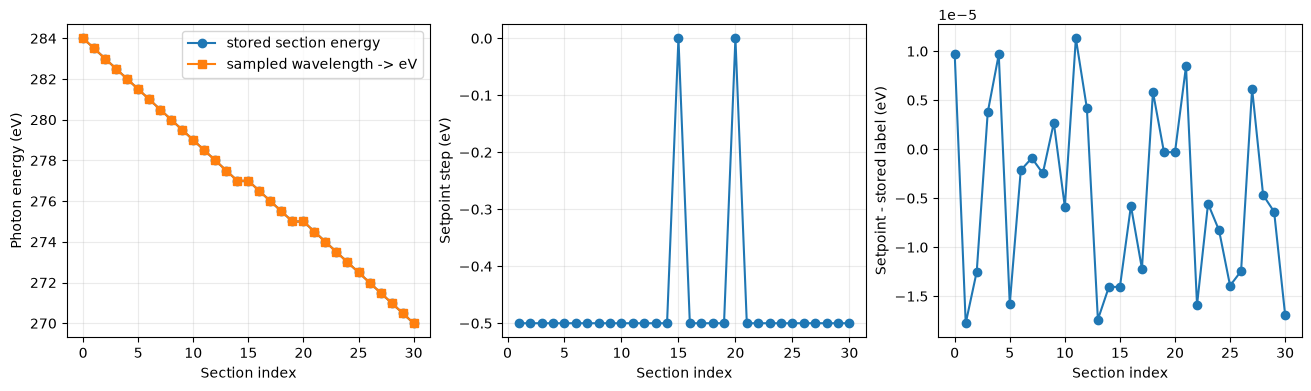

In [55]:
from historical import review_diagnostics as review
SECTION_H5 = config.XAS_STATIC_DIR / 'run58794_static_xas.h5'
SECTION_METADATA_SAMPLES = 8
SECTION_EXPECTED_STEP_EV = None       # e.g. -0.5 only if that scan protocol is known
SECTION_EXPECTED_ENERGIES_EV = None   # explicit planned values, if available; never guessed
SECTION_STEP_TOL_EV = 0.08
SECTION_REPEAT_TOL_EV = 0.08
SECTION_MATCH_TOL_EV = 0.001
section_summary, section_metadata = review.section_energy_summary(
    SECTION_H5, SECTION_METADATA_SAMPLES, SECTION_EXPECTED_STEP_EV,
    SECTION_STEP_TOL_EV, SECTION_REPEAT_TOL_EV, SECTION_MATCH_TOL_EV)
print('Section input:', SECTION_H5.resolve(), '| metadata:', section_metadata)
print(section_summary[['section', 'nominal_eV', 'section_raw_eV', 'shots', 'setpoint_eV',
                       'setpoint_step_eV', 'duplicate_previous_setpoint', 'setpoint_label_disagree']].to_string(index=False))
print('Missing stored energies:', section_summary.loc[~np.isfinite(section_summary.nominal_eV), 'section'].tolist(),
      '| empty sections:', section_summary.loc[section_summary.shots == 0, 'section'].tolist())
print('Stored/raw disagreements:', section_summary.loc[section_summary.stored_raw_disagree, 'section'].tolist())
section_groups = section_summary.groupby('nominal_eV', dropna=True).agg(
    n_sections=('section','size'), sections=('section',list), recorded_shots=('shots','sum'))
print('Repeated stored energy labels (all sections, not only adjacent):')
print(section_groups.loc[section_groups.n_sections > 1].to_string())
section_steps = np.diff(section_summary.nominal_eV.to_numpy())
print('Stored energy ordering:', 'nondecreasing' if np.all(section_steps >= 0) else
      'nonincreasing' if np.all(section_steps <= 0) else 'mixed')
if SECTION_EXPECTED_STEP_EV is not None:
    print('Unexpected sampled setpoint steps:', section_summary.loc[
        (~section_summary.step_matches_expected) & (section_summary.section > 0), 'section'].tolist())
if SECTION_EXPECTED_ENERGIES_EV is not None:
    section_present = section_summary.nominal_eV.to_numpy()
    section_missing = [value for value in SECTION_EXPECTED_ENERGIES_EV if not np.any(
        np.isclose(section_present, value, atol=SECTION_MATCH_TOL_EV, rtol=0))]
    print('Planned energies not represented by stored labels:', section_missing)
else:
    print('No scan plan supplied: absent intended energies cannot be determined automatically.')
section_fig, section_axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
section_axes[0].plot(section_summary.section, section_summary.nominal_eV, 'o-', label='stored section energy')
section_axes[0].plot(section_summary.section, section_summary.setpoint_eV, 's-', label='sampled wavelength -> eV')
section_axes[0].set(xlabel='Section index', ylabel='Photon energy (eV)'); section_axes[0].legend()
section_axes[1].plot(section_summary.section, section_summary.setpoint_step_eV, 'o-')
if SECTION_EXPECTED_STEP_EV is not None:
    section_axes[1].axhline(SECTION_EXPECTED_STEP_EV, color='black', lw=1, ls='--')
section_axes[1].set(xlabel='Section index', ylabel='Setpoint step (eV)')
section_axes[2].plot(section_summary.section, section_summary.setpoint_minus_nominal_eV, 'o-')
section_axes[2].set(xlabel='Section index', ylabel='Setpoint - stored label (eV)')
for section_axis in section_axes: section_axis.grid(alpha=.25)
plt.show()
